We have a list of influencer compaigns with features and revenues. The target variable is `campaign_revenue_usd` while the other columns are features we can use to train ML models to predict revenues. ML can also help us pinpoint which factors contribute significantly to revenue growth.

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import f_regression, SelectFpr
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor

from sklearn.pipeline import Pipeline

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [4]:
inf_data = pd.read_csv('./influencer_campaign_regression.csv')

In [5]:
inf_data.head()

,creator_followers_k,engagement_rate_pct,paid_boost_spend_usd,avg_watch_time_sec,promo_discount_pct,content_format,audience_intent_tier,caption_word_count,hashtags_used_count,creator_phone_os,contract_payment_terms,posting_day_weather,campaign_revenue_usd
0,425.4,2.14,1331.0,35.2,10,Static-Carousel,High-Intent-Niche,35,16,Android,Net-30,Sunny,15192.26
1,171.3,5.73,3925.0,25.4,10,YouTube-Deep-Dive,Lifestyle-Warm,26,16,Android,Upfront,Cloudy,20018.44
2,356.4,8.03,1817.0,9.4,0,Short-Video-Reel,High-Intent-Niche,43,24,Android,Upfront,Cloudy,21146.87
3,272.2,7.70,942.0,32.1,15,Short-Video-Reel,Lifestyle-Warm,113,9,Android,Net-15,Rainy,17639.62
4,143.0,6.06,3347.0,51.0,20,Short-Video-Reel,Broad-Entertainment,72,18,Android,Net-30,Cloudy,17375.60


In [6]:
inf_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   creator_followers_k     3000 non-null   float64
 1   engagement_rate_pct     3000 non-null   float64
 2   paid_boost_spend_usd    3000 non-null   float64
 3   avg_watch_time_sec      3000 non-null   float64
 4   promo_discount_pct      3000 non-null   int64  
 5   content_format          3000 non-null   str    
 6   audience_intent_tier    3000 non-null   str    
 7   caption_word_count      3000 non-null   int64  
 8   hashtags_used_count     3000 non-null   int64  
 9   creator_phone_os        3000 non-null   str    
 10  contract_payment_terms  3000 non-null   str    
 11  posting_day_weather     3000 non-null   str    
 12  campaign_revenue_usd    3000 non-null   float64
dtypes: float64(5), int64(3), str(5)
memory usage: 304.8 KB


In [7]:
numerical_features = inf_data.select_dtypes(include=['int64', 'float64']).columns.to_list()
categorical_features = inf_data.select_dtypes(include=['object']).columns.to_list()

print('Numerical Features:', numerical_features)
print('Categorical Features:', categorical_features)

Numerical Features: ['creator_followers_k', 'engagement_rate_pct', 'paid_boost_spend_usd', 'avg_watch_time_sec', 'promo_discount_pct', 'caption_word_count', 'hashtags_used_count', 'campaign_revenue_usd']
Categorical Features: ['content_format', 'audience_intent_tier', 'creator_phone_os', 'contract_payment_terms', 'posting_day_weather']


C:\Users\buzz\AppData\Local\Temp\ipykernel_14472\748933831.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = inf_data.select_dtypes(include=['object']).columns.to_list()


In [8]:
inf_data.describe()

,creator_followers_k,engagement_rate_pct,paid_boost_spend_usd,avg_watch_time_sec,promo_discount_pct,caption_word_count,hashtags_used_count,campaign_revenue_usd
count,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,232.592433,5.161417,2317.529667,30.266467,12.358333,86.810000,12.367000,16678.699140
std,126.675186,2.539730,1273.365953,14.147323,8.613245,42.942674,6.996473,4747.136562
min,15.000000,0.800000,100.000000,6.100000,0.000000,12.000000,1.000000,2915.630000
25%,122.400000,2.927500,1208.750000,17.900000,5.000000,50.000000,6.000000,13222.897500
50%,229.800000,5.180000,2370.000000,30.400000,10.000000,86.000000,13.000000,16480.745000
75%,343.725000,7.410000,3416.250000,42.700000,20.000000,124.000000,18.000000,19839.157500
max,449.900000,9.500000,4499.000000,55.000000,25.000000,159.000000,24.000000,32527.890000


In [9]:
inf_data.loc[inf_data.duplicated()]

,creator_followers_k,engagement_rate_pct,paid_boost_spend_usd,avg_watch_time_sec,promo_discount_pct,content_format,audience_intent_tier,caption_word_count,hashtags_used_count,creator_phone_os,contract_payment_terms,posting_day_weather,campaign_revenue_usd


In [10]:
inf_data.isnull().sum()

creator_followers_k       0
engagement_rate_pct       0
paid_boost_spend_usd      0
avg_watch_time_sec        0
promo_discount_pct        0
content_format            0
audience_intent_tier      0
caption_word_count        0
hashtags_used_count       0
creator_phone_os          0
contract_payment_terms    0
posting_day_weather       0
campaign_revenue_usd      0
dtype: int64

In [11]:
rows = []

for feature in numerical_features:
    Q1 = inf_data[feature].quantile(0.25)
    Q3 = inf_data[feature].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    below = (inf_data[feature] < lower_bound).sum()
    above = (inf_data[feature] > upper_bound).sum()
    total = below + above

    rows.append({
        'feature': feature,
        'lower_bound': lower_bound,
        'upper_bound': upper_bound,
        'below_lower': below,
        'above_upper': above,
        'outlier_count': total,
        'outlier_pct': round(total / inf_data[feature].notna().sum() * 100, 2),
    })

outlier_summary = (
    pd.DataFrame(rows)
    .set_index('feature')
    .sort_values('outlier_count', ascending=False)
)

display(outlier_summary)

,lower_bound,upper_bound,below_lower,above_upper,outlier_count,outlier_pct
feature,,,,,,
campaign_revenue_usd,3298.50750,29763.54750,1,8,9,0.3
creator_followers_k,-209.58750,675.71250,0,0,0,0.0
paid_boost_spend_usd,-2102.50000,6727.50000,0,0,0,0.0
engagement_rate_pct,-3.79625,14.13375,0,0,0,0.0
avg_watch_time_sec,-19.30000,79.90000,0,0,0,0.0
promo_discount_pct,-17.50000,42.50000,0,0,0,0.0
caption_word_count,-61.00000,235.00000,0,0,0,0.0
hashtags_used_count,-12.00000,36.00000,0,0,0,0.0


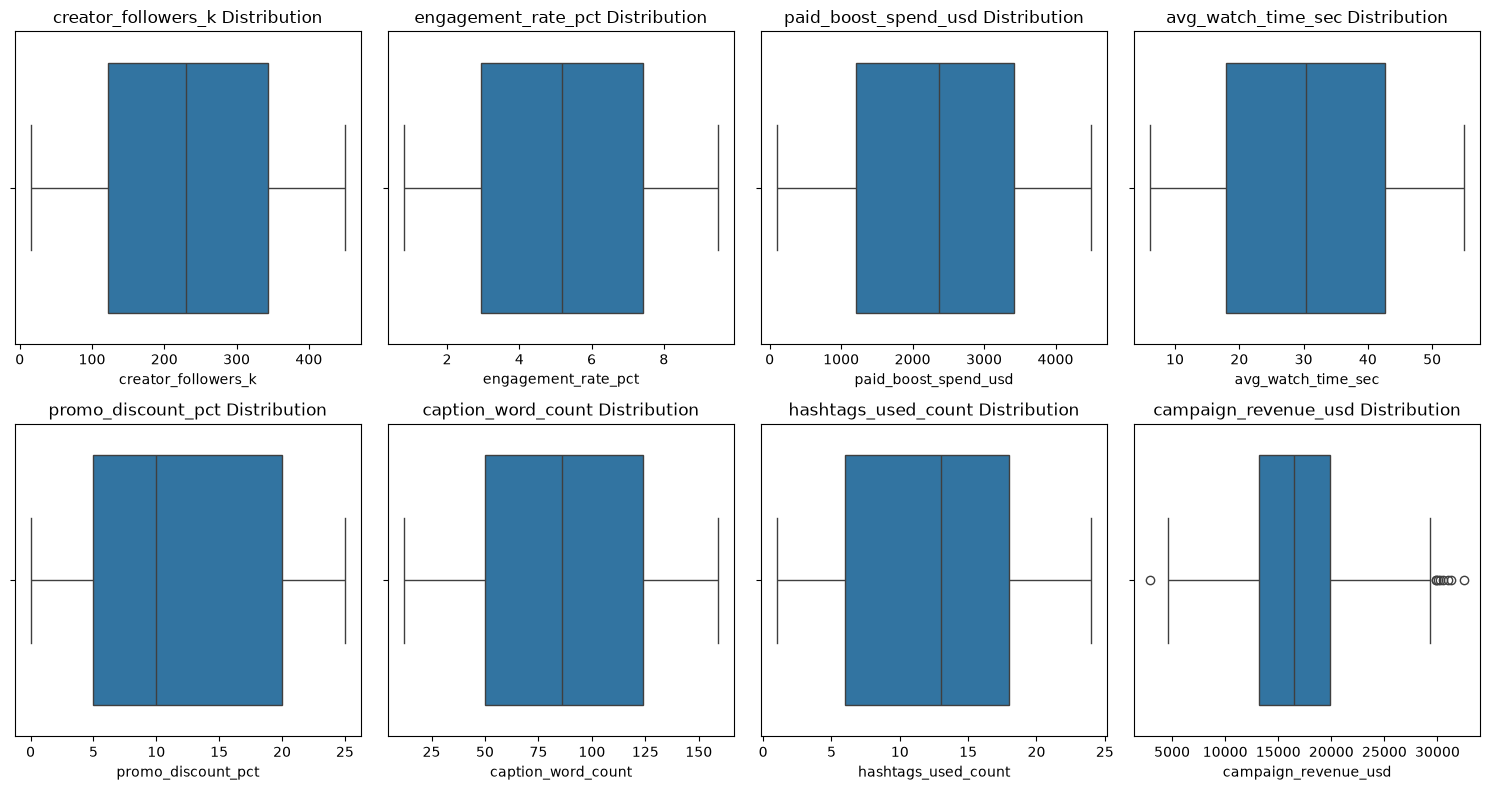

,mean,count
content_format,,
Short-Video-Reel,16633.0,1518
Static-Carousel,15051.0,734
YouTube-Deep-Dive,18369.0,748


,mean,count
audience_intent_tier,,
Broad-Entertainment,15200.0,1034
High-Intent-Niche,18472.0,751
Lifestyle-Warm,16828.0,1215


,mean,count
creator_phone_os,,
Android,16640.0,1530
iOS,16719.0,1470


,mean,count
contract_payment_terms,,
Net-15,16755.0,1024
Net-30,16516.0,998
Upfront,16765.0,978


,mean,count
posting_day_weather,,
Cloudy,16675.0,1018
Rainy,16852.0,957
Sunny,16520.0,1025


In [12]:
fig, axes = plt.subplots(2, 4, figsize=(15, 8))
axes = axes.flatten()

for i, feature in enumerate(numerical_features):
  sns.boxplot(data=inf_data, x=feature, ax=axes[i])
  axes[i].set_title(f'{feature} Distribution')

plt.tight_layout()
plt.show()

for feature in categorical_features:
    display(inf_data.groupby(feature)['campaign_revenue_usd'].agg(['mean', 'count']).round(0))

# Insights

*   Looking at the describe table, all numerical columns show little to no skewness which means values are largely symmetric.
*   Judging from the boxplots and outlier summary, there are no outliers in the numerical columns aside from the target revenue column `campaign_revenue_usd` which has 0.3% outliers which are negligible.
*   `audience_intent_tier` and `content_format` are meaningful drivers. High-Intent-Niche campaigns average about \$18.5k versus about \$15.2k for Broad-Entertainment, and YouTube-Deep-Dive averages about \$18.4k versus about \$15.1k for Static-Carousel.
*   There are no missing values in data.
*   There are no duplicates in data.

,creator_followers_k,engagement_rate_pct,paid_boost_spend_usd,avg_watch_time_sec,promo_discount_pct,caption_word_count,hashtags_used_count,campaign_revenue_usd
creator_followers_k,1.000000,0.008232,-0.039713,-0.014288,0.000145,-0.027796,-0.004817,0.519312
engagement_rate_pct,0.008232,1.000000,0.015172,0.051056,0.012178,0.024897,-0.024634,0.536494
paid_boost_spend_usd,-0.039713,0.015172,1.000000,0.008782,0.000353,-0.014132,0.027906,0.456036
avg_watch_time_sec,-0.014288,0.051056,0.008782,1.000000,0.008975,0.011263,0.004782,0.198176
promo_discount_pct,0.000145,0.012178,0.000353,0.008975,1.000000,-0.003278,-0.016193,0.203321
caption_word_count,-0.027796,0.024897,-0.014132,0.011263,-0.003278,1.000000,0.021713,-0.010518
hashtags_used_count,-0.004817,-0.024634,0.027906,0.004782,-0.016193,0.021713,1.000000,0.006891
campaign_revenue_usd,0.519312,0.536494,0.456036,0.198176,0.203321,-0.010518,0.006891,1.000000


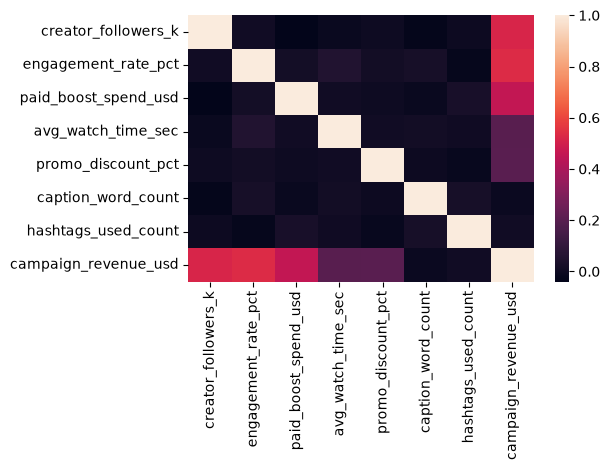

In [13]:
corr = inf_data[numerical_features].corr()

display(corr)

sns.heatmap(corr)
plt.tight_layout()
plt.show()

# Strong-to-moderate positive relationships

*   `creator_followers_k` (~0.55): Revenue tends to rise with creator audience size.
*   `engagement_rate_pct` (~0.55): Higher engagement goes with higher revenue, about as strongly as follower count.
*   `paid_boost_spend_usd` (~0.45): More paid boosting is moderately associated with more revenue.

# Weak positive relationships

*   `avg_watch_time_sec` (~0.2): A small positive link.
*   `promo_discount_pct` (~0.2): Also a small positive link.

# Essentially no relationship

*   `caption_word_count` (~0): No visible link to revenue.
*   `hashtags_used_count` (~0): No visible link to revenue.

In [14]:
inf_data.drop_duplicates(inplace=True)
inf_data.dropna(inplace=True)
inf_data.reset_index()

,index,creator_followers_k,engagement_rate_pct,paid_boost_spend_usd,avg_watch_time_sec,promo_discount_pct,content_format,audience_intent_tier,caption_word_count,hashtags_used_count,creator_phone_os,contract_payment_terms,posting_day_weather,campaign_revenue_usd
0,0,425.4,2.14,1331.0,35.2,10,Static-Carousel,High-Intent-Niche,35,16,Android,Net-30,Sunny,15192.26
1,1,171.3,5.73,3925.0,25.4,10,YouTube-Deep-Dive,Lifestyle-Warm,26,16,Android,Upfront,Cloudy,20018.44
2,2,356.4,8.03,1817.0,9.4,0,Short-Video-Reel,High-Intent-Niche,43,24,Android,Upfront,Cloudy,21146.87
3,3,272.2,7.70,942.0,32.1,15,Short-Video-Reel,Lifestyle-Warm,113,9,Android,Net-15,Rainy,17639.62
4,4,143.0,6.06,3347.0,51.0,20,Short-Video-Reel,Broad-Entertainment,72,18,Android,Net-30,Cloudy,17375.60
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2995,2995,284.3,4.83,2364.0,42.6,15,Short-Video-Reel,Broad-Entertainment,142,17,iOS,Upfront,Sunny,16226.79
2996,2996,158.8,4.56,394.0,36.7,0,Short-Video-Reel,Lifestyle-Warm,73,1,Android,Net-15,Sunny,10195.99
2997,2997,110.4,8.45,2110.0,9.3,20,YouTube-Deep-Dive,Lifestyle-Warm,75,13,iOS,Net-30,Rainy,17171.79
2998,2998,31.0,7.54,546.0,22.0,25,Short-Video-Reel,Broad-Entertainment,135,6,Android,Net-30,Rainy,9633.00


In [ ]:
numerical_features = [c for c in numerical_features if c != 'campaign_revenue_usd']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ])

In [16]:
X = inf_data.drop(columns=['campaign_revenue_usd'])
y = inf_data['campaign_revenue_usd']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [17]:
pipeline_lr = Pipeline(steps=[('preprocessor', preprocessor),
                               ('feature_selection', SelectFpr(f_regression, alpha=0.05)),
                               ('regressor', LinearRegression())])

param_grid_lr = {
    'feature_selection__alpha': [0.01, 0.05, 0.1],
    'regressor__fit_intercept': [True, False],
}

grid_search_lr = GridSearchCV(pipeline_lr, param_grid_lr, cv=3, scoring='neg_mean_squared_error', n_jobs=-1, verbose=1)
grid_search_lr.fit(X_train, y_train)

print(f"Best parameters for Linear Regression: {grid_search_lr.best_params_}")
print(f"Best RMSE for Linear Regression: {np.sqrt(-grid_search_lr.best_score_):.2f}")

Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best parameters for Linear Regression: {'feature_selection__alpha': 0.05, 'regressor__fit_intercept': True}
Best RMSE for Linear Regression: 776.14


In [18]:
pipeline_rf = Pipeline(steps=[('preprocessor', preprocessor),
                               ('feature_selection', SelectFpr(f_regression, alpha=0.05)),
                               ('regressor', RandomForestRegressor())])

param_grid_rf = {
    'regressor__n_estimators': [200, 500],
    'regressor__max_depth': [None, 10, 20],
    'regressor__min_samples_leaf': [1, 5, 10],
    'regressor__max_features': ['sqrt', 1.0],
}

grid_search_rf = GridSearchCV(pipeline_rf, param_grid_rf, cv=3, scoring='neg_mean_squared_error', n_jobs=-1, verbose=1)
grid_search_rf.fit(X_train, y_train)

print(f"Best parameters for Random Forest: {grid_search_rf.best_params_}")
print(f"Best RMSE for Random Forest: {np.sqrt(-grid_search_rf.best_score_):.2f}")

Fitting 3 folds for each of 36 candidates, totalling 108 fits
Best parameters for Random Forest: {'regressor__max_depth': None, 'regressor__max_features': 'sqrt', 'regressor__min_samples_leaf': 1, 'regressor__n_estimators': 500}
Best RMSE for Random Forest: 1378.68


In [19]:
pipeline_knn = Pipeline(steps=[('preprocessor', preprocessor),
                               ('feature_selection', SelectFpr(f_regression, alpha=0.05)),
                               ('regressor', KNeighborsRegressor())])

param_grid_knn = {
    'regressor__n_neighbors': [3, 5, 10, 20],
    'regressor__weights': ['uniform', 'distance'],
    'regressor__p': [1, 2],
}

grid_search_knn = GridSearchCV(pipeline_knn, param_grid_knn, cv=3, scoring='neg_mean_squared_error', n_jobs=-1, verbose=1)
grid_search_knn.fit(X_train, y_train)

print(f"Best parameters for K Nearest Neighbors: {grid_search_knn.best_params_}")
print(f"Best RMSE for K Nearest Neighbors: {np.sqrt(-grid_search_knn.best_score_):.2f}")

Fitting 3 folds for each of 16 candidates, totalling 48 fits
Best parameters for K Nearest Neighbors: {'regressor__n_neighbors': 10, 'regressor__p': 2, 'regressor__weights': 'distance'}
Best RMSE for K Nearest Neighbors: 1320.95


In [20]:
best_models = {
    'LinearRegression': {'model': grid_search_lr.best_estimator_, 'rmse': np.sqrt(-grid_search_lr.best_score_)},
    'RandomForest': {'model': grid_search_rf.best_estimator_, 'rmse': np.sqrt(-grid_search_rf.best_score_)},
    'KNearestNeighbors': {'model': grid_search_knn.best_estimator_, 'rmse': np.sqrt(-grid_search_knn.best_score_)}
}

best_model_name = min(best_models, key=lambda k: best_models[k]['rmse'])
best_model_info = best_models[best_model_name]

print(f"The best model is {best_model_name} with an RMSE of {best_model_info['rmse']:.2f}")

The best model is LinearRegression with an RMSE of 776.14


,cv_rmse,test_rmse,test_mae,test_r2
model,,,,
LinearRegression,776.141,799.462,630.994,0.973
RandomForest,1378.676,1291.706,1023.090,0.928
KNearestNeighbors,1320.952,1250.381,966.718,0.933


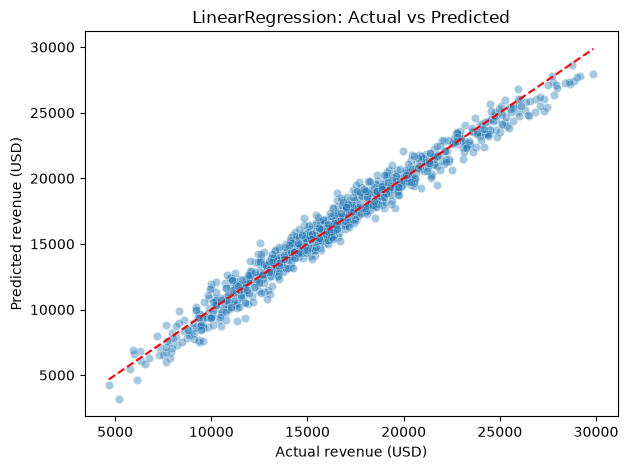

In [21]:
results = []
for name, info in best_models.items():
    y_pred = info['model'].predict(X_test)
    results.append({
        'model': name,
        'cv_rmse': info['rmse'],
        'test_rmse': np.sqrt(mean_squared_error(y_test, y_pred)),
        'test_mae': mean_absolute_error(y_test, y_pred),
        'test_r2': r2_score(y_test, y_pred),
    })

results_df = pd.DataFrame(results).set_index('model').round(3)
display(results_df)

best_pred = best_model_info['model'].predict(X_test)
residuals = y_test - best_pred

sns.scatterplot(x=y_test, y=best_pred, alpha=0.4)
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, 'r--')
plt.xlabel('Actual revenue (USD)')
plt.ylabel('Predicted revenue (USD)')
plt.title(f'{best_model_name}: Actual vs Predicted')

plt.tight_layout()
plt.show()

In [24]:
joblib.dump(best_model_info['model'], 'influencer_revenue_model.pkl')

['influencer_revenue_model.pkl']